In [1]:
!pip install pandas numpy scikit-learn matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
print("Notebook is running from:", os.getcwd())
print()
print("Files here:", os.listdir("."))
print()
if os.path.isdir("data"):
    print("Files in data/:", os.listdir("data"))
else:
    print("No 'data' folder here yet")

Notebook is running from: c:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\adhd200_project_ML

Files here: ['.git', 'ADHD200_Pipeline .ipynb', 'data', 'output', 'phenotypic_baseline.ipynb', 'README.md', 'scripts']

Files in data/: ['ADHD200_CC200_TCs_filtfix', 'ADHD200_testing_pheno', 'ADHD200_training_pheno', 'NITRC-multi-file-downloads', 'outputs']


In [4]:
from pathlib import Path

for name in ["ADHD200_training_pheno", "ADHD200_testing_pheno"]:
    p = Path("data") / name
    print(f"\n=== {p}  (is folder: {p.is_dir()}) ===")
    if p.is_dir():
        for f in sorted(p.rglob("*")):
            if f.is_file():
                print(f"  {f.relative_to(p)}   {f.stat().st_size:,} bytes")
    else:
        print("  it's a single file, size:", p.stat().st_size, "bytes")


=== data\ADHD200_training_pheno  (is folder: True) ===
  KKI\KKI_phenotypic.csv   7,368 bytes
  NeuroIMAGE\NeuroIMAGE_phenotypic.csv   3,211 bytes
  NYU\NYU_phenotypic.csv   19,335 bytes
  OHSU\OHSU_phenotypic.csv   7,512 bytes
  Peking_1\Peking_1_phenotypic.csv   7,559 bytes
  Peking_2\Peking_2_phenotypic.csv   6,109 bytes
  Peking_3\Peking_3_phenotypic.csv   3,920 bytes
  Pittsburgh\Pittsburgh_phenotypic.csv   8,571 bytes
  WashU\WashU_phenotypic.csv   7,868 bytes

=== data\ADHD200_testing_pheno  (is folder: True) ===
  Brown\Brown_TestRelease_phenotypic.csv   3,832 bytes
  KKI\KKI_TestRelease_phenotypic.csv   1,747 bytes
  NeuroIMAGE\NeuroIMAGE_TestRelease_phenotypic.csv   3,461 bytes
  NYU\NYU_TestRelease_phenotypic.csv   5,784 bytes
  OHSU\OHSU_TestRelease_phenotypic.csv   5,603 bytes
  Peking_1\Peking_1_TestRelease_phenotypic.csv   6,542 bytes
  Pittsburgh\Pittsburgh_TestRelease_phenotypic.csv   1,478 bytes


In [5]:
import re, warnings
import numpy as np
import pandas as pd
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 40)

TRAIN_PATH = Path("data/ADHD200_training_pheno")
TEST_PATH  = Path("data/ADHD200_testing_pheno")

def read_all(root):
    frames = []
    for f in sorted(root.rglob("*.csv")):
        df = pd.read_csv(f, sep=None, engine="python", encoding_errors="replace")
        df["site_folder"] = f.parent.name          # site name comes from the folder
        df["source_file"] = f.name
        frames.append(df)
    return frames

train_frames = read_all(TRAIN_PATH)
test_frames  = read_all(TEST_PATH)
print(f"train files: {len(train_frames)}   test files: {len(test_frames)}")

# Do all files share the same columns?
for label, frames in [("TRAIN", train_frames), ("TEST", test_frames)]:
    print(f"\n=== {label}: columns per file ===")
    base = list(frames[0].columns)
    print("first file columns:", base)
    for df in frames:
        cols = list(df.columns)
        diff_missing = [c for c in base if c not in cols]
        diff_extra   = [c for c in cols if c not in base]
        status = "same" if not diff_missing and not diff_extra else f"missing={diff_missing} extra={diff_extra}"
        print(f"  {df.site_folder.iloc[0]:12s} rows={len(df):4d}  {status}")

train files: 9   test files: 7

=== TRAIN: columns per file ===
first file columns: ['ScanDir ID', 'Site', 'Gender', 'Age', 'Handedness', 'DX', 'Secondary Dx ', 'ADHD Measure', 'ADHD Index', 'Inattentive', 'Hyper/Impulsive', 'IQ Measure', 'Verbal IQ', 'Performance IQ', 'Full2 IQ', 'Full4 IQ', 'Med Status', 'QC_Rest_1', 'QC_Rest_2', 'QC_Rest_3', 'QC_Rest_4', 'QC_Anatomical_1', 'QC_Anatomical_2', 'site_folder', 'source_file']
  KKI          rows=  83  same
  NeuroIMAGE   rows=  48  same
  NYU          rows= 222  same
  OHSU         rows=  79  same
  Peking_1     rows=  85  same
  Peking_2     rows=  67  same
  Peking_3     rows=  42  same
  Pittsburgh   rows=  89  same
  WashU        rows=  61  missing=['ScanDir ID', 'QC_Rest_1', 'QC_Rest_2', 'QC_Rest_3', 'QC_Rest_4', 'QC_Anatomical_1', 'QC_Anatomical_2'] extra=['ScanDirID', 'Study #', 'QC_S1_Rest_1', 'QC_S1_Rest_2', 'QC_S1_Rest_3', 'QC_S1_Rest_4', 'QC_S1_Rest_5', 'QC_S1_Rest_6', 'QC_S1_Anat', 'QC_S2_Rest_1', 'QC_S2_Rest_2', 'QC_S2_Anat'

In [6]:
for label, frames in [("TRAIN", train_frames), ("TEST", test_frames)]:
    print(f"\n=== {label}: DX value counts, by site ===")
    for df in frames:
        counts = df["DX"].astype(str).str.strip().value_counts(dropna=False).to_dict()
        print(f"  {df.site_folder.iloc[0]:12s} {counts}")

# also see how the Site column is coded vs the folder names
print("\n=== Site column vs folder name ===")
for df in train_frames + test_frames:
    print(f"  folder={df.site_folder.iloc[0]:12s} Site column values={df['Site'].unique().tolist()}")


=== TRAIN: DX value counts, by site ===
  KKI          {'0': 61, '1': 16, '3': 5, '2': 1}
  NeuroIMAGE   {'0': 23, '1': 18, '2': 6, '3': 1}
  NYU          {'0': 99, '1': 77, '3': 44, '2': 2}
  OHSU         {'0': 42, '1': 23, '3': 12, '2': 2}
  Peking_1     {'0': 61, '3': 17, '1': 7}
  Peking_2     {'0': 32, '3': 20, '1': 15}
  Peking_3     {'0': 23, '3': 12, '1': 7}
  Pittsburgh   {'0': 89}
  WashU        {'0': 61}

=== TEST: DX value counts, by site ===
  Brown        {'withheld': 26}
  KKI          {'withheld': 11}
  NeuroIMAGE   {'withheld': 25}
  NYU          {'withheld': 41}
  OHSU         {'withheld': 34}
  Peking_1     {'withheld': 51}
  Pittsburgh   {'withheld': 9}

=== Site column vs folder name ===
  folder=KKI          Site column values=[3]
  folder=NeuroIMAGE   Site column values=[4]
  folder=NYU          Site column values=[5]
  folder=OHSU         Site column values=[6]
  folder=Peking_1     Site column values=[1]
  folder=Peking_2     Site column values=[1]
  folder=Pe

## Step 1: Load and inspect the raw phenotypic files

**What we did**
- Pointed the notebook at the two phenotypic folders: `data/ADHD200_training_pheno` and `data/ADHD200_testing_pheno`.
- Read every per-site CSV with `rglob`, because each site sits in its own subfolder.
- Took the site name from the **folder name**, saved as `site_folder`, and the source file name as `source_file`.
- Compared the column names across all files.
- Counted `DX` values per site and compared the `Site` column with the folder names.

**What we found**

| Item | Result |
|---|---|
| Training files / rows | 9 sites, 776 subjects |
| Testing files / rows | 7 sites, 197 subjects |
| Columns | Identical across files except WashU, which spells the ID column `ScanDirID` and uses different QC column names. Harmless: we normalise column names and never use the QC columns. |
| Training labels | `DX` is 0 (control), 1, 2 or 3 (ADHD subtypes) |
| Training class counts | 491 controls and 285 ADHD (the report has 488 and 280, so 8 subjects were dropped last week) |
| Testing labels | Every test row is `withheld`, so there is nothing to score against |
| Site column | Peking_1, Peking_2 and Peking_3 all have `Site = 1` (the mislabeled site ID noted in the report) |
| Single-class sites | Pittsburgh (89) and WashU (61) contain only controls |

**Decisions**
1. **Drop the official train → test split.** The test labels are withheld. We evaluate on the 776 training subjects with mixed-site 5-fold and leave-one-site-out (LOSO), as in the report.
2. **Use the folder name as the site.** The `Site` column merges the three Peking sites, which would break LOSO. The folder name gives the 9 sites in the report.
3. **Match last week's subject set (768).** We will compare subject IDs against the connectivity folder `ADHD200_CC200_TCs_filtfix`.
4. **Expect undefined AUC for Pittsburgh and WashU in LOSO.** With one class, AUC cannot be computed, so these sites are skipped in the per-site AUC but kept in the pooled metrics.

**Next:** Step 2 normalises the column names, inspects Gender, Handedness and the `-999` codes, and checks the connectivity folder to find the 768 subjects.

In [7]:
def _norm(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

KEEP = {"scandirid": "subject_id", "sitefolder": "site", "gender": "sex", "age": "age",
        "handedness": "handedness", "dx": "dx", "verbaliq": "viq",
        "performanceiq": "piq", "full4iq": "fiq", "full2iq": "fiq2"}

def normalise(df):
    d = df.copy()
    d.columns = [_norm(c) for c in d.columns]
    d = d[[c for c in KEEP if c in d.columns]].rename(columns=KEEP)
    return d

train_df = pd.concat([normalise(f) for f in train_frames], ignore_index=True)
print("rows:", len(train_df), "| unique subject IDs:", train_df["subject_id"].nunique())
print("missing subject_id:", train_df["subject_id"].isna().sum())

print("\nRaw Gender values:\n", train_df["sex"].value_counts(dropna=False).to_string())
print("\nRaw Handedness values:\n", train_df["handedness"].value_counts(dropna=False).to_string())

print("\nCount of -999 / pending / blank codes per column:")
for c in ["age", "viq", "piq", "fiq", "fiq2", "handedness", "sex"]:
    s = train_df[c].astype(str).str.strip()
    print(f"  {c:11s} -999: {(s.isin(['-999','-999.0'])).sum():4d}   "
          f"pending: {(s.str.lower()=='pending').sum():3d}   NaN: {train_df[c].isna().sum():4d}")

display(train_df.head())

rows: 776 | unique subject IDs: 776
missing subject_id: 0

Raw Gender values:
 sex
1.0    488
0.0    287
NaN      1

Raw Handedness values:
 handedness
 1.00      555
 0.00       20
 0.91       15
 0.82       11
 0.83       10
 0.52        7
-999.00      6
 0.76        6
 0.57        6
 0.65        6
 0.75        5
 0.74        4
 0.69        4
 0.67        4
 0.60        4
 0.86        4
 0.45        4
 0.68        4
 0.55        4
 0.29        4
 0.50        4
 0.31        4
 0.33        4
 0.43        4
 0.16        3
 0.46        3
 0.64        3
 0.95        3
 0.58        3
 0.73        3
 0.62        3
 0.21        3
 0.42        3
 0.47        3
 0.40        2
 0.24        2
 0.56        2
 0.39        2
 0.36        2
 0.54        2
 0.81        2
 0.38        2
 0.13        2
 0.77        2
 0.11        2
 3.00        1
 2.00        1
 0.26        1
 0.71        1
 0.19        1
 0.27        1
 0.80        1
 0.44        1
 0.20        1
 0.22        1
 0.79        1
 0.05   

,subject_id,site,sex,age,handedness,dx,viq,piq,fiq,fiq2
0,1018959,KKI,0.0,12.36,1.0,0,99.0,115.0,103.0,NaN
1,1019436,KKI,1.0,12.98,1.0,3,124.0,108.0,122.0,NaN
2,1043241,KKI,1.0,9.12,1.0,0,128.0,106.0,120.0,NaN
3,1266183,KKI,0.0,9.67,1.0,0,136.0,96.0,120.0,NaN
4,1535233,KKI,1.0,9.64,0.0,0,106.0,135.0,122.0,NaN


In [8]:
num = train_df.copy()
for c in ["handedness", "viq", "piq", "fiq", "fiq2"]:
    num[c] = pd.to_numeric(num[c], errors="coerce").mask(lambda s: s <= -999)

print("Subjects with handedness > 1:")
display(num.loc[num.handedness > 1, ["subject_id", "site", "handedness"]])

print("\nHandedness by site:")
display(num.groupby("site").handedness.agg(
    n="count", min="min", median="median", max="max",
    frac_exactly_1=lambda s: (s == 1).mean()).round(2))

print("\nFraction MISSING by site:")
display(num[["viq", "piq", "fiq", "fiq2"]].isna().groupby(num.site).mean().round(2))

Subjects with handedness > 1:


,subject_id,site,handedness
13,1735881,KKI,2.0
99,2876903,NeuroIMAGE,3.0



Handedness by site:


,n,min,median,max,frac_exactly_1
site,,,,,
KKI,83,0.0,1.00,2.0,0.90
NYU,215,-0.2,0.65,1.0,0.10
NeuroIMAGE,48,0.0,1.00,3.0,0.88
OHSU,79,1.0,1.00,1.0,1.00
Peking_1,85,0.0,1.00,1.0,0.99
Peking_2,67,0.0,1.00,1.0,0.97
Peking_3,42,1.0,1.00,1.0,1.00
Pittsburgh,89,0.0,1.00,1.0,0.96
WashU,61,1.0,1.00,1.0,1.00



Fraction MISSING by site:


,viq,piq,fiq,fiq2
site,,,,
KKI,0.01,0.01,0.01,1.00
NYU,0.05,0.05,0.05,1.00
NeuroIMAGE,1.00,1.00,1.00,1.00
OHSU,1.00,1.00,0.00,1.00
Peking_1,0.00,0.00,0.00,1.00
Peking_2,0.01,0.01,0.01,1.00
Peking_3,0.00,0.00,0.00,1.00
Pittsburgh,0.47,0.47,0.00,0.47
WashU,1.00,1.00,0.00,1.00


In [9]:
df = train_df.copy()

# 1. numeric columns: -999 -> NaN
for c in ["age", "handedness", "viq", "piq", "fiq", "dx"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").mask(lambda s: s <= -999)

# 2. handedness: out-of-range -> NaN, then right-handed (score > 0) vs not
df.loc[df["handedness"] > 1, "handedness"] = np.nan
df["right_handed"] = (df["handedness"] > 0).astype(float).where(df["handedness"].notna())

# 3. sex, ids, site, label
df["sex"] = df["sex"].map({1.0: "M", 0.0: "F"})          # ADHD-200: 1 = male, 0 = female
df["subject_id"] = df["subject_id"].astype(str)
df["site"] = df["site"].astype(str)                      # folder name, NOT the Site column
assert df["dx"].notna().all(), "some diagnoses are missing"
df["y"] = (df["dx"] > 0).astype(int)                     # 1 = any ADHD subtype

# 4. columns we model with (viq / piq / fiq2 deliberately left out)
MODEL_COLS = ["age", "sex", "right_handed", "fiq", "site"]
df = df[["subject_id", "site", "y"] + MODEL_COLS[:-1]].reset_index(drop=True)
y = df["y"]

# --- checks ---
print(f"subjects: {len(df)}   ADHD: {int(y.sum())}   control: {int((1 - y).sum())}")
print(f"majority-class accuracy: {max(y.mean(), 1 - y.mean()):.3f}\n")

print("Missing fraction (modelling columns):")
display(df[["age", "sex", "right_handed", "fiq"]].isna().mean().round(3).to_frame("missing").T)

print("\nBy site:")
display(df.groupby("site").agg(
    n=("y", "size"), adhd_rate=("y", "mean"), age_mean=("age", "mean"),
    male_rate=("sex", lambda s: (s == "M").mean()),
    right_handed=("right_handed", "mean"), fiq_mean=("fiq", "mean")).round(2))

subjects: 776   ADHD: 285   control: 491
majority-class accuracy: 0.633

Missing fraction (modelling columns):


,age,sex,right_handed,fiq
missing,0.0,0.001,0.012,0.077



By site:


,n,adhd_rate,age_mean,male_rate,right_handed,fiq_mean
site,,,,,,
KKI,83,0.27,10.24,0.55,0.91,109.89
NYU,222,0.55,11.59,0.65,0.98,108.05
NeuroIMAGE,48,0.52,16.99,0.65,0.89,NaN
OHSU,79,0.47,8.84,0.54,1.00,113.76
Peking_1,85,0.28,11.24,0.42,0.99,112.73
Peking_2,67,0.52,12.12,0.99,0.97,116.18
Peking_3,42,0.45,13.24,1.00,1.00,108.62
Pittsburgh,89,0.00,15.11,0.52,0.96,109.81
WashU,61,0.00,11.47,0.54,1.00,116.11


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

def build_pipe(num, cat, model):
    parts = []
    if num:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),   # no missing indicator on purpose
                                       ("sc", StandardScaler())]), num))
    if cat:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return Pipeline([("prep", ColumnTransformer(parts)), ("clf", model)])

def safe_auc(y_true, p):
    return roc_auc_score(y_true, p) if len(np.unique(y_true)) == 2 else np.nan

def evaluate(df, num, cat, make_model, splits):
    """splits = list of (name, train_idx, test_idx)."""
    X, yv = df[num + cat], df["y"].values
    rows, all_p, all_y = [], [], []
    for name, tr, te in splits:
        pipe = build_pipe(num, cat, make_model()).fit(X.iloc[tr], yv[tr])
        p = pipe.predict_proba(X.iloc[te])[:, 1]
        yhat = (p >= 0.5).astype(int)
        rows.append(dict(fold=name, n_test=len(te), adhd_rate=yv[te].mean(), auc=safe_auc(yv[te], p),
                         bal_acc=balanced_accuracy_score(yv[te], yhat), f1=f1_score(yv[te], yhat, zero_division=0)))
        all_p.append(p); all_y.append(yv[te])
    all_p, all_y = np.concatenate(all_p), np.concatenate(all_y)
    pooled = dict(AUC_mean=np.nanmean([r["auc"] for r in rows]), AUC_pooled=safe_auc(all_y, all_p),
                  BalAcc=balanced_accuracy_score(all_y, (all_p >= 0.5).astype(int)),
                  F1=f1_score(all_y, (all_p >= 0.5).astype(int), zero_division=0))
    return pooled, pd.DataFrame(rows)

# --- mixed-site 5-fold splits ---
idx = np.arange(len(df))
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
mixed_splits = [(f"fold{k}", tr, te) for k, (tr, te) in enumerate(skf.split(idx, df["y"]))]

LR = lambda: LogisticRegression(max_iter=2000, class_weight="balanced")

# --- sanity check: a model that ignores the features should give AUC ~0.5 ---
dummy_res, _ = evaluate(df, ["age"], [], lambda: DummyClassifier(strategy="prior"), mixed_splits)
print("Dummy (no information) pooled AUC:", round(dummy_res["AUC_pooled"], 3))

# --- setup A: age + sex ---
res_A, folds_A = evaluate(df, num=["age"], cat=["sex"], make_model=LR, splits=mixed_splits)
print("\nSetup A | mixed 5-fold | LogReg")
display(folds_A.round(3))
print({k: round(v, 3) for k, v in res_A.items()})

Dummy (no information) pooled AUC: 0.499

Setup A | mixed 5-fold | LogReg


,fold,n_test,adhd_rate,auc,bal_acc,f1
0,fold0,156,0.365,0.675,0.617,0.573
1,fold1,155,0.368,0.546,0.523,0.469
2,fold2,155,0.368,0.735,0.731,0.672
3,fold3,155,0.368,0.706,0.639,0.583
4,fold4,155,0.368,0.675,0.656,0.611


{'AUC_mean': np.float64(0.667), 'AUC_pooled': 0.658, 'BalAcc': 0.633, 'F1': 0.581}


In [11]:
# LOSO splits: hold out one whole site per rotation
loso_splits = [(s, idx[df.site != s], idx[df.site == s]) for s in sorted(df.site.unique())]

res_A_loso, folds_A_loso = evaluate(df, num=["age"], cat=["sex"], make_model=LR, splits=loso_splits)
print("Setup A | LOSO | LogReg")
display(folds_A_loso.round(3))
print({k: round(v, 3) for k, v in res_A_loso.items()})

# Direct comparison with the mixed result
print("\nMixed vs LOSO (pooled AUC):", round(res_A["AUC_pooled"], 3), "->", round(res_A_loso["AUC_pooled"], 3))

Setup A | LOSO | LogReg


,fold,n_test,adhd_rate,auc,bal_acc,f1
0,KKI,83,0.265,0.505,0.494,0.353
1,NYU,222,0.554,0.697,0.656,0.729
2,NeuroIMAGE,48,0.521,0.687,0.578,0.323
3,OHSU,79,0.468,0.653,0.649,0.650
4,Peking_1,85,0.282,0.792,0.736,0.610
5,Peking_2,67,0.522,0.395,0.516,0.693
6,Peking_3,42,0.452,0.453,0.500,0.623
7,Pittsburgh,89,0.000,NaN,0.483,0.000
8,WashU,61,0.000,NaN,0.492,0.000


{'AUC_mean': np.float64(0.597), 'AUC_pooled': 0.639, 'BalAcc': 0.621, 'F1': 0.571}

Mixed vs LOSO (pooled AUC): 0.658 -> 0.639


In [12]:
X, yv = df[["age", "sex"]], df["y"].values
rows = []
for name, tr, te in loso_splits:
    pipe = build_pipe(["age"], ["sex"], LR()).fit(X.iloc[tr], yv[tr])
    p = pipe.predict_proba(X.iloc[te])[:, 1]
    rows.append(dict(site=name, actual_adhd_rate=yv[te].mean(), mean_predicted_prob=p.mean(),
                     frac_predicted_adhd=(p >= 0.5).mean()))
display(pd.DataFrame(rows).round(2))

,site,actual_adhd_rate,mean_predicted_prob,frac_predicted_adhd
0,KKI,0.27,0.50,0.55
1,NYU,0.55,0.50,0.66
2,NeuroIMAGE,0.52,0.33,0.12
3,OHSU,0.47,0.51,0.54
4,Peking_1,0.28,0.44,0.41
5,Peking_2,0.52,0.60,0.99
6,Peking_3,0.45,0.58,1.00
7,Pittsburgh,0.00,0.44,0.52
8,WashU,0.00,0.47,0.51


In [13]:
from sklearn.ensemble import RandomForestClassifier

RF = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                    random_state=SEED, n_jobs=-1)
MODELS = {"LogReg": LR, "RandForest": RF}

B_NUM = ["age", "right_handed", "fiq"]
SETUPS = {
    "A": dict(num=["age"],  cat=["sex"],          splits=["mixed", "loso"], desc="age + sex"),
    "B": dict(num=B_NUM,    cat=["sex"],          splits=["mixed", "loso"], desc="age, sex, handedness, FIQ"),
    "C": dict(num=[],       cat=["site"],         splits=["mixed"],         desc="site only"),
    "D": dict(num=B_NUM,    cat=["sex", "site"],  splits=["mixed"],         desc="B + site"),
}
SPLITS = {"mixed": mixed_splits, "loso": loso_splits}

results, fold_tables = [], []
for setup, cfg in SETUPS.items():
    for split in cfg["splits"]:
        for mname, mk in MODELS.items():
            pooled, folds = evaluate(df, cfg["num"], cfg["cat"], mk, SPLITS[split])
            results.append(dict(setup=setup, features=cfg["desc"], split=split, model=mname, **pooled))
            fold_tables.append(folds.assign(setup=setup, split=split, model=mname))

res = pd.DataFrame(results)
folds_all = pd.concat(fold_tables, ignore_index=True)

print(f"Majority-class accuracy: {max(y.mean(), 1 - y.mean()):.3f}   |   chance AUC: 0.5")
print("Last week's connectivity baseline (E): mixed AUC 0.632, LOSO AUC 0.516\n")
display(res.round(3))

print("\nPooled AUC by setup:")
display(res.pivot_table(index=["setup", "features"], columns=["split", "model"], values="AUC_pooled").round(3))

print("\nMean per-site AUC (LOSO only, within-site ranking):")
display(res[res.split == "loso"].pivot_table(index=["setup", "features"], columns="model", values="AUC_mean").round(3))

Majority-class accuracy: 0.633   |   chance AUC: 0.5
Last week's connectivity baseline (E): mixed AUC 0.632, LOSO AUC 0.516



,setup,features,split,model,AUC_mean,AUC_pooled,BalAcc,F1
0,A,age + sex,mixed,LogReg,0.667,0.658,0.633,0.581
1,A,age + sex,mixed,RandForest,0.567,0.562,0.531,0.440
2,A,age + sex,loso,LogReg,0.597,0.639,0.621,0.571
3,A,age + sex,loso,RandForest,0.542,0.537,0.524,0.430
4,B,"age, sex, handedness, FIQ",mixed,LogReg,0.717,0.713,0.633,0.560
5,B,"age, sex, handedness, FIQ",mixed,RandForest,0.691,0.687,0.620,0.539
6,B,"age, sex, handedness, FIQ",loso,LogReg,0.712,0.697,0.644,0.572
7,B,"age, sex, handedness, FIQ",loso,RandForest,0.657,0.643,0.597,0.502
8,C,site only,mixed,LogReg,0.724,0.711,0.696,0.643
9,C,site only,mixed,RandForest,0.716,0.705,0.696,0.643



Pooled AUC by setup:


split                             loso             mixed           
model                           LogReg RandForest LogReg RandForest
setup features                                                     
A     age + sex                  0.639      0.537  0.658      0.562
B     age, sex, handedness, FIQ  0.697      0.643  0.713      0.687
C     site only                    NaN        NaN  0.711      0.705
D     B + site                     NaN        NaN  0.814      0.809


Mean per-site AUC (LOSO only, within-site ranking):


,model,LogReg,RandForest
setup,features,,
A,age + sex,0.597,0.542
B,"age, sex, handedness, FIQ",0.712,0.657


In [14]:
loso_sites = (folds_all[folds_all.split == "loso"]
              .pivot_table(index="fold", columns=["setup", "model"], values="auc").round(3))
display(loso_sites)

setup           A                 B           
model      LogReg RandForest LogReg RandForest
fold                                          
KKI         0.505      0.477  0.522      0.497
NYU         0.697      0.623  0.712      0.689
NeuroIMAGE  0.687      0.600  0.675      0.622
OHSU        0.653      0.520  0.755      0.704
Peking_1    0.792      0.605  0.903      0.867
Peking_2    0.395      0.473  0.656      0.607
Peking_3    0.453      0.497  0.760      0.616

In [15]:
# 1. Per-site LOSO AUC for setups A and B
loso_sites = (folds_all[folds_all.split == "loso"]
              .pivot_table(index="fold", columns=["setup", "model"], values="auc").round(3))
display(loso_sites)

# 2. Which variable drives B's gain? (LOSO, LogReg)
ABLATION = {
    "age + sex (A)":     (["age"], ["sex"]),
    "A + FIQ":           (["age", "fiq"], ["sex"]),
    "A + handedness":    (["age", "right_handed"], ["sex"]),
    "A + both (B)":      (["age", "right_handed", "fiq"], ["sex"]),
    "FIQ only":          (["fiq"], []),
    "handedness only":   (["right_handed"], []),
}
rows = []
for name, (num, cat) in ABLATION.items():
    pooled, _ = evaluate(df, num, cat, LR, loso_splits)
    rows.append(dict(features=name, AUC_pooled=pooled["AUC_pooled"], AUC_mean_per_site=pooled["AUC_mean"]))
display(pd.DataFrame(rows).round(3))

setup           A                 B           
model      LogReg RandForest LogReg RandForest
fold                                          
KKI         0.505      0.477  0.522      0.497
NYU         0.697      0.623  0.712      0.689
NeuroIMAGE  0.687      0.600  0.675      0.622
OHSU        0.653      0.520  0.755      0.704
Peking_1    0.792      0.605  0.903      0.867
Peking_2    0.395      0.473  0.656      0.607
Peking_3    0.453      0.497  0.760      0.616

,features,AUC_pooled,AUC_mean_per_site
0,age + sex (A),0.639,0.597
1,A + FIQ,0.699,0.714
2,A + handedness,0.631,0.591
3,A + both (B),0.697,0.712
4,FIQ only,0.635,0.667
5,handedness only,0.437,0.493


In [16]:
# --- out-of-fold predictions for each candidate model (logistic regression) ---
def oof_predictions(df, num, cat, make_model, splits):
    X, yv_ = df[num + cat], df["y"].values
    p = np.full(len(df), np.nan)
    for name, tr, te in splits:
        pipe = build_pipe(num, cat, make_model()).fit(X.iloc[tr], yv_[tr])
        p[te] = pipe.predict_proba(X.iloc[te])[:, 1]
    return p

CANDS = {
    "A":     (["age"], ["sex"]),
    "A+FIQ": (["age", "fiq"], ["sex"]),
    "B":     (B_NUM, ["sex"]),
    "C":     ([], ["site"]),
    "D":     (B_NUM, ["sex", "site"]),
}
RUNS = {"loso": ["A", "A+FIQ", "B"], "mixed": ["A", "A+FIQ", "B", "C", "D"]}
SPL = {"loso": loso_splits, "mixed": mixed_splits}

P = {(split, name): oof_predictions(df, *CANDS[name], LR, SPL[split])
     for split, names in RUNS.items() for name in names}

# --- paired bootstrap: resample subjects within each site ---
yv, site_arr = df["y"].values, df["site"].values
sites = np.unique(site_arr)
rng = np.random.default_rng(SEED)
site_ix = [np.where(site_arr == s)[0] for s in sites]
N_BOOT = 1000
draws = [np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in site_ix]) for _ in range(N_BOOT)]

def metrics(ix, p):
    yb, pb, sb = yv[ix], p[ix], site_arr[ix]
    per = [safe_auc(yb[sb == s], pb[sb == s]) for s in sites]
    return safe_auc(yb, pb), np.nanmean(per)

full = np.arange(len(df))
POINT = {k: metrics(full, p) for k, p in P.items()}
BOOT  = {k: np.array([metrics(ix, p) for ix in draws]) for k, p in P.items()}   # shape (N_BOOT, 2)

def fmt(point, arr):
    lo, hi = np.nanpercentile(arr, [2.5, 97.5])
    return f"{point:.3f}  [{lo:.3f}, {hi:.3f}]"

rows = [dict(split=s, setup=n, pooled_AUC=fmt(POINT[(s, n)][0], BOOT[(s, n)][:, 0]),
             mean_per_site_AUC=fmt(POINT[(s, n)][1], BOOT[(s, n)][:, 1])) for (s, n) in P]
print("AUC with 95% bootstrap intervals (logistic regression):")
display(pd.DataFrame(rows))

# --- paired differences ---
DIFFS = [("loso", "A+FIQ", "A"), ("loso", "B", "A+FIQ"), ("loso", "B", "A"),
         ("mixed", "B", "A"), ("mixed", "B", "C"), ("mixed", "D", "B")]
out = []
for s, a, b in DIFFS:
    d_point = (POINT[(s, a)][0] - POINT[(s, b)][0], POINT[(s, a)][1] - POINT[(s, b)][1])
    d_boot = BOOT[(s, a)] - BOOT[(s, b)]
    out.append(dict(split=s, comparison=f"{a} - {b}",
                    pooled_diff=fmt(d_point[0], d_boot[:, 0]),
                    per_site_diff=fmt(d_point[1], d_boot[:, 1])))
print("\nPaired differences (interval excluding 0 = bigger than evaluation noise):")
display(pd.DataFrame(out))

AUC with 95% bootstrap intervals (logistic regression):


,split,setup,pooled_AUC,mean_per_site_AUC
0,loso,A,"0.639 [0.602, 0.678]","0.597 [0.543, 0.651]"
1,loso,A+FIQ,"0.699 [0.662, 0.736]","0.714 [0.666, 0.764]"
2,loso,B,"0.697 [0.659, 0.734]","0.712 [0.666, 0.761]"
3,mixed,A,"0.658 [0.623, 0.697]","0.588 [0.537, 0.641]"
4,mixed,A+FIQ,"0.716 [0.681, 0.751]","0.710 [0.662, 0.758]"
5,mixed,B,"0.713 [0.678, 0.748]","0.708 [0.660, 0.756]"
6,mixed,C,"0.711 [0.677, 0.742]","0.366 [0.318, 0.415]"
7,mixed,D,"0.814 [0.787, 0.843]","0.694 [0.644, 0.743]"



Paired differences (interval excluding 0 = bigger than evaluation noise):


,split,comparison,pooled_diff,per_site_diff
0,loso,A+FIQ - A,"0.060 [0.030, 0.089]","0.116 [0.066, 0.167]"
1,loso,B - A+FIQ,"-0.003 [-0.006, -0.000]","-0.002 [-0.008, 0.004]"
2,loso,B - A,"0.057 [0.027, 0.086]","0.114 [0.063, 0.165]"
3,mixed,B - A,"0.055 [0.027, 0.084]","0.120 [0.071, 0.170]"
4,mixed,B - C,"0.003 [-0.043, 0.052]","0.342 [0.280, 0.409]"
5,mixed,D - B,"0.101 [0.078, 0.126]","-0.015 [-0.026, -0.004]"


In [17]:
def group_holdout(df, test_sites):
    tr = np.where(~df.site.isin(test_sites))[0]
    te = np.where(df.site.isin(test_sites))[0]
    return [("holdout", tr, te)]

SCENARIOS = {
    "test KKI + OHSU":               ["KKI", "OHSU"],
    "test NeuroIMAGE + NYU":         ["NeuroIMAGE", "NYU"],
    "test all Peking (1,2,3)":       ["Peking_1", "Peking_2", "Peking_3"],
}
FEATURE_SETS = {"A (age+sex)": (["age"], ["sex"]), "B (age, sex, IQ, hand.)": (B_NUM, ["sex"])}

rows = []
for scen, test_sites in SCENARIOS.items():
    sp = group_holdout(df, test_sites)
    te = sp[0][2]
    for fname, (num, cat) in FEATURE_SETS.items():
        p = oof_predictions(df.assign(), num, cat, LR, sp)[te]       # predictions on test sites only
        y_te, s_te = df.y.values[te], df.site.values[te]
        per = {s: safe_auc(y_te[s_te == s], p[s_te == s]) for s in test_sites}
        rows.append(dict(scenario=scen, features=fname, n_train=len(sp[0][1]), n_test=len(te),
                         test_adhd_rate=round(y_te.mean(), 2),
                         pooled_auc=round(safe_auc(y_te, p), 3),
                         mean_within_site_auc=round(np.nanmean(list(per.values())), 3)))
display(pd.DataFrame(rows))

,scenario,features,n_train,n_test,test_adhd_rate,pooled_auc,mean_within_site_auc
0,test KKI + OHSU,A (age+sex),614,162,0.36,0.622,0.579
1,test KKI + OHSU,"B (age, sex, IQ, hand.)",614,162,0.36,0.638,0.636
2,test NeuroIMAGE + NYU,A (age+sex),506,270,0.55,0.692,0.691
3,test NeuroIMAGE + NYU,"B (age, sex, IQ, hand.)",506,270,0.55,0.698,0.698
4,"test all Peking (1,2,3)",A (age+sex),582,194,0.40,0.639,0.547
5,"test all Peking (1,2,3)","B (age, sex, IQ, hand.)",582,194,0.40,0.808,0.762


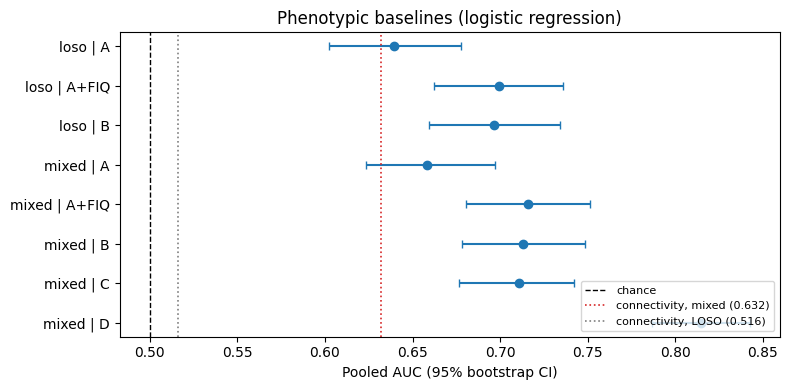

Saved: ['phenotypic_auc_summary.png', 'phenotypic_bootstrap_ci_logreg.csv', 'phenotypic_clean_dataset.csv', 'phenotypic_per_fold.csv', 'phenotypic_summary_all_models.csv']


In [18]:
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("output"); OUT.mkdir(exist_ok=True)       # your project already has an 'output' folder

def ci(arr): return np.nanpercentile(arr, [2.5, 97.5])

# tidy CI table (numeric, so it can be plotted and reused)
ci_rows = []
for (s, n), (pooled, per_site) in POINT.items():
    lo_p, hi_p = ci(BOOT[(s, n)][:, 0]); lo_s, hi_s = ci(BOOT[(s, n)][:, 1])
    ci_rows.append(dict(split=s, setup=n, pooled_auc=pooled, pooled_lo=lo_p, pooled_hi=hi_p,
                        per_site_auc=per_site, per_site_lo=lo_s, per_site_hi=hi_s))
ci_table = pd.DataFrame(ci_rows)

# save everything
res.round(4).to_csv(OUT / "phenotypic_summary_all_models.csv", index=False)
folds_all.round(4).to_csv(OUT / "phenotypic_per_fold.csv", index=False)
ci_table.round(4).to_csv(OUT / "phenotypic_bootstrap_ci_logreg.csv", index=False)
df.to_csv(OUT / "phenotypic_clean_dataset.csv", index=False)

# summary plot: pooled AUC with 95% CI, vs last week's connectivity baseline
fig, ax = plt.subplots(figsize=(8, 4))
plot = ci_table[~((ci_table.split == "loso") & (ci_table.setup.isin(["C", "D"])))].reset_index(drop=True)
labels = plot.split + " | " + plot.setup
y_pos = np.arange(len(plot))[::-1]
ax.errorbar(plot.pooled_auc, y_pos, xerr=[plot.pooled_auc - plot.pooled_lo, plot.pooled_hi - plot.pooled_auc],
            fmt="o", capsize=3)
ax.axvline(0.5, color="k", ls="--", lw=1, label="chance")
ax.axvline(0.632, color="tab:red", ls=":", lw=1.2, label="connectivity, mixed (0.632)")
ax.axvline(0.516, color="tab:gray", ls=":", lw=1.2, label="connectivity, LOSO (0.516)")
ax.set_yticks(y_pos); ax.set_yticklabels(labels); ax.set_xlabel("Pooled AUC (95% bootstrap CI)")
ax.set_title("Phenotypic baselines (logistic regression)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "phenotypic_auc_summary.png", dpi=150); plt.show()

print("Saved:", sorted(p.name for p in OUT.glob("phenotypic_*")))